In [ ]:
%pip install category_encoders
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 5.2 MB/s eta 0:00:00


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression , LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from category_encoders import OneHotEncoder , TargetEncoder
from scipy.sparse import hstack , csr_matrix
from sklearn.preprocessing import StandardScaler

In [7]:
data = pd.read_csv('mental_health_cleaned.csv')

In [8]:
feature_cols = ['Code',
                'Schizophrenia disorders (share of population)',
                'Depressive disorders (share of population)',
                'Anxiety disorders (share of population)',
                'Bipolar disorders (share of population)']
x = data[feature_cols]
y = data['Year']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [9]:
import pandas as pd
from scipy.sparse import hstack, csr_matrix
from sklearn.linear_model import LinearRegression
from category_encoders import OneHotEncoder
from sklearn.model_selection import train_test_split # Added import for train_test_split

# Re-define feature columns and perform train-test split for self-containment
feature_cols = ['Code',
                'Schizophrenia disorders (share of population)',
                'Depressive disorders (share of population)',
                'Anxiety disorders (share of population)',
                'Bipolar disorders (share of population)']
x = data[feature_cols]
y = data['Year']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Separate categorical and numerical features
categorical_cols = ['Code']
print(f"Type of x_train: {type(x_train)}")
print(f"Shape of x_train: {x_train.shape}")
print(f"x_train head:\n{x_train.head()}")
numerical_cols = [col for col in x_train.columns if col not in categorical_cols]

# Initialize OneHotEncoder
encoder = OneHotEncoder(handle_unknown='indicator')

# Fit and transform categorical features for training data
# OneHotEncoder already returns a sparse matrix (csr_matrix by default)
x_train_categorical_encoded_sparse = encoder.fit_transform(x_train[categorical_cols])

# Transform categorical features for testing data
# This also returns a sparse matrix (csr_matrix by default)
x_test_categorical_encoded_sparse = encoder.transform(x_test[categorical_cols])

# Convert numerical features to sparse matrix
# .values extracts the numpy array, .astype(float) ensures correct type, csr_matrix converts to sparse
x_train_numerical_sparse = csr_matrix(x_train[numerical_cols].values.astype(float))
x_test_numerical_sparse = csr_matrix(x_test[numerical_cols].values.astype(float))

# Concatenate encoded categorical features with numerical features (both as sparse matrices)
x_train_encoded = hstack([x_train_categorical_encoded_sparse, x_train_numerical_sparse])
x_test_encoded = hstack([x_test_categorical_encoded_sparse, x_test_numerical_sparse])

model = LinearRegression()
model.fit(x_train_encoded, y_train)

Type of x_train: <class 'pandas.core.frame.DataFrame'>
Shape of x_train: (5136, 5)
x_train head:
     Code  Schizophrenia disorders (share of population)  \
6080  USA                                       0.460500   
2345  GUM                                       0.329679   
509   BHR                                       0.270948   
5461  SUR                                       0.271088   
4586  PHL                                       0.290620   

      Depressive disorders (share of population)  \
6080                                    4.506475   
2345                                    3.158780   
509                                     4.528089   
5461                                    4.471186   
4586                                    2.756981   

      Anxiety disorders (share of population)  \
6080                                 5.800745   
2345                                 3.914000   
509                                  4.937836   
5461                             

LinearRegression()

In [10]:
predictions = model.predict(x_test_encoded)
print("predictions:", predictions.round(2))
print("year:", y_test)
print(f"Mean Squared Error: {mean_squared_error(y_test, predictions):.2f}")

predictions: [2001.75 2005.47 2007.2  ... 2001.76 2004.27 2005.48]
year: 324     2014
1340    2010
6025    2015
2077    1997
381     2011
        ... 
151     1991
1498    2018
1033    2003
915     2005
1623    1993
Name: Year, Length: 1284, dtype: int64
Mean Squared Error: 70.49


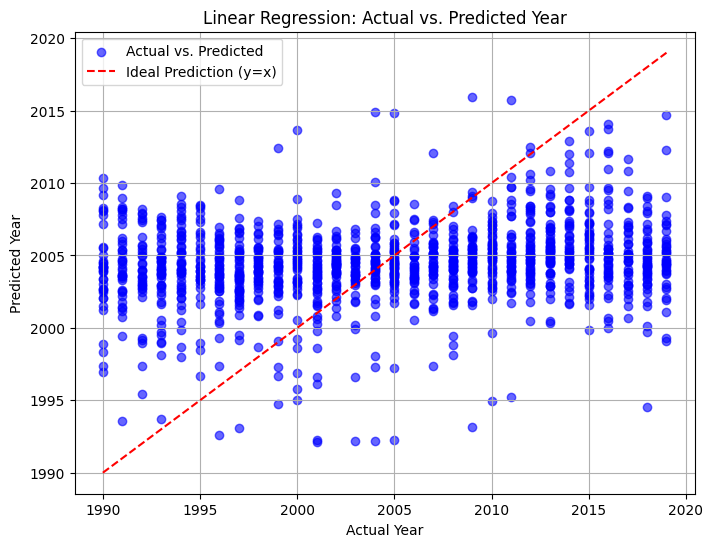

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, alpha=0.6, color='blue', label='Actual vs. Predicted')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Ideal Prediction (y=x)') # Add a 45-degree line for reference
plt.xlabel('Actual Year')
plt.ylabel('Predicted Year')
plt.title('Linear Regression: Actual vs. Predicted Year')
plt.legend()
plt.grid(True)
plt.show()